# 06 – Unusual payments

Tests that flag payments for a second look. A flag is **not** proof of error or fraud; it marks something an auditor would want to check, and many flagged payments will have a simple explanation. Supplier names in this notebook are working notes taken from the council's published spending data. Tests use Procurement payments only, excluding `REDACTED`.

In [40]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("../data/processed/procurement.db")

def q(sql):
    return pd.read_sql(sql, conn)

pd.options.display.float_format = "{:,.1f}".format

## Test 1 – Possible duplicate payments

Same supplier, same amount (£1,000 or more) and same payment date, but under **different transaction numbers**.

In [41]:
conn.execute("DROP VIEW IF EXISTS dup_suspects")
conn.execute("""
CREATE TEMP VIEW dup_suspects AS
SELECT supplier_clean, pay_date, amount,
       COUNT(*) AS lines,
       COUNT(DISTINCT transaction_number) AS transactions
FROM payments
WHERE spend_group = 'Procurement'
  AND supplier_clean <> 'REDACTED'
  AND amount >= 1000
GROUP BY supplier_clean, pay_date, amount
HAVING COUNT(DISTINCT transaction_number) > 1
""")

q("""
SELECT COUNT(*) AS suspect_groups,
       ROUND(SUM(amount * (transactions - 1)) / 1e6, 2) AS possible_overpaid_millions
FROM dup_suspects
""")

,suspect_groups,possible_overpaid_millions
0,1210,14.0


In [42]:
q("""
SELECT supplier_clean, pay_date, amount, lines, transactions
FROM dup_suspects
ORDER BY amount * (transactions - 1) DESC
LIMIT 15
""")

,supplier_clean,pay_date,amount,lines,transactions
0,EDAROTH LTD,2026-03-26,"423,177.9",2,2
1,MOTUS COMMERCIALS T A MOTUS GROUP UK LTD,2025-09-17,"22,215.0",16,16
2,PRELON ESTATES LTD,2026-03-12,"30,870.0",10,10
3,SLM LTD,2025-08-13,"250,000.0",2,2
4,WINCKWORTH SHERWOOD LLP,2024-07-23,"215,000.0",2,2
5,TRITON SECURITY AND FACILITIES MANAGEMENT LTD,2024-05-21,"106,630.1",3,3
6,WINCKWORTH SHERWOOD LLP,2024-07-23,"165,000.0",2,2
7,TRITON SECURITY AND FACILITIES MANAGEMENT LTD,2024-05-21,"78,544.6",3,3
8,SURESERVE COMPLIANCE FIRE LTD,2025-01-03,"78,335.9",3,3
9,SLM LTD,2025-07-16,"150,000.0",2,2


### Narrowing to priority pairs

Many repeats are batches or instalments (e.g. 16 identical payments on one day). Exactly **two** identical payments with the same spend type and service area (£5,000 or more) are the stronger duplicate signal.

In [43]:
conn.execute("DROP VIEW IF EXISTS dup_pairs")
conn.execute("""
CREATE TEMP VIEW dup_pairs AS
SELECT supplier_clean, pay_date, amount, expense_type, service_area,
       COUNT(DISTINCT transaction_number) AS transactions
FROM payments
WHERE spend_group = 'Procurement'
  AND supplier_clean <> 'REDACTED'
  AND amount >= 5000
GROUP BY supplier_clean, pay_date, amount, expense_type, service_area
HAVING COUNT(DISTINCT transaction_number) = 2
""")

q("""
SELECT COUNT(*) AS priority_pairs,
       ROUND(SUM(amount) / 1e6, 2) AS possible_overpaid_millions
FROM dup_pairs
""")

,priority_pairs,possible_overpaid_millions
0,215,5.9


In [44]:
q("""
SELECT supplier_clean, pay_date, amount, expense_type, service_area
FROM dup_pairs
ORDER BY amount DESC
LIMIT 12
""")

,supplier_clean,pay_date,amount,expense_type,service_area
0,EDAROTH LTD,2026-03-26,"423,177.9",New Construction,Capital - New Build / Land Enabling Works
1,SLM LTD,2025-08-13,"250,000.0",External Professional Fees,Capital - Pending Approvals - NH05 - Sports Pr...
2,WINCKWORTH SHERWOOD LLP,2024-07-23,"215,000.0",Acquisition of Buildings,Capital - New Build / Land Enabling Works
3,WINCKWORTH SHERWOOD LLP,2024-07-23,"165,000.0",Acquisition of Buildings,Capital - New Build / Land Enabling Works
4,SLM LTD,2025-07-16,"150,000.0",External Professional Fees,Capital - Pending Approvals - NH05 - Sports Pr...
5,STANNAH LIFT SERVICES LTD,2024-04-04,"147,981.3","Plant, Equipment & Machinery",Capital - Investment In Blocks - Planned
6,CHASE SERVICES GROUP LTD,2025-07-16,"123,476.0",Services - Fees and Charges,Planned Programmes Overheads - Net Expenditure
7,WEST OF ENGLAND COMBINED AUTHORITY,2024-09-06,"110,000.0",Services - Supplies and Services to service users,Policy and Communications
8,AMERESCO LTD,2025-02-21,"104,895.1","Conversion, Renovation & Improvement",Capital - Heat Decarb - Spend to Save 1 - 3001466
9,ETM CONTRACTORS LTD,2025-01-31,"100,000.0","Conversion, Renovation & Improvement",Capital - Carriageway Reconstruction/Resurfacing


In [45]:
q("""
SELECT payment_id, supplier, pay_date, amount, transaction_number, expense_type, service_area, project
FROM payments
WHERE supplier_clean = 'EDAROTH LTD'
  AND pay_date = '2026-03-26'
  AND ABS(amount - 423177.9) < 0.01
""")

,payment_id,supplier,pay_date,amount,transaction_number,expense_type,service_area,project


In [46]:
q("""
SELECT payment_id, supplier_clean, pay_date,
       printf('%.2f', amount) AS amount,
       transaction_number, expense_type, service_area, project
FROM payments
WHERE (supplier_clean = 'EDAROTH LTD' AND pay_date = '2026-03-26')
   OR (supplier_clean = 'SLM LTD'     AND pay_date = '2025-08-13')
ORDER BY supplier_clean, transaction_number
""")

,payment_id,supplier_clean,pay_date,amount,transaction_number,expense_type,service_area,project
0,136730,EDAROTH LTD,2026-03-26,423177.92,31281237,New Construction,Capital - New Build / Land Enabling Works,TA permanent new build
1,136731,EDAROTH LTD,2026-03-26,423177.92,31281703,New Construction,Capital - New Build / Land Enabling Works,TA permanent new build
2,99378,SLM LTD,2025-08-13,250000.00,31233832,External Professional Fees,Capital - Pending Approvals - NH05 - Sports Pr...,Pending Approvals - NH05 - Sports Provision
3,99379,SLM LTD,2025-08-13,250000.00,31233833,External Professional Fees,Capital - Pending Approvals - NH05 - Sports Pr...,Pending Approvals - NH05 - Sports Provision


### Test 1 findings

- A broad test (same supplier, amount and date, different transactions; £1,000 or more) flags **1,210 groups, up to £14.0m**. Many are batches of identical charges (e.g. 16 payments of £22,215 to Motus on one day), so this is an upper bound.
- Narrowing to **exactly two** identical payments with the same spend type and service area (£5,000 or more) gives **215 priority pairs, up to £5.9m**.
- Examples for review: **Edaroth Ltd**, two payments of £423,177.92 on 26 Mar 2026 for the same project, with transaction numbers 31281237 and 31281703; **SLM Ltd**, two payments of £250,000.00 on 13 Aug 2025 for the same project, with consecutive transaction numbers.
- These are items to review, not confirmed errors: two identical payments can be legitimate stage payments. The data has no invoice numbers, so it cannot show whether they relate to separate invoices.

## Test 2 – Payments bunched just below round limits

People sometimes keep payments just under an approval limit. If more payments sit just **below** a round amount than just **above** it, that is worth a look. The limits below (£10,000, £25,000, £50,000) are **illustrative**, not the council's actual approval limits, which are not in the data. A ratio near 1 means no bunching.

In [47]:
q("""
SELECT threshold, just_below, just_above,
       ROUND(1.0 * just_below / just_above, 2) AS ratio
FROM (
    SELECT 10000 AS threshold,
           SUM(amount >= 9000  AND amount < 10000) AS just_below,
           SUM(amount >= 10000 AND amount < 11000) AS just_above
    FROM payments WHERE spend_group = 'Procurement' AND supplier_clean <> 'REDACTED'
    UNION ALL
    SELECT 25000,
           SUM(amount >= 22500 AND amount < 25000),
           SUM(amount >= 25000 AND amount < 27500)
    FROM payments WHERE spend_group = 'Procurement' AND supplier_clean <> 'REDACTED'
    UNION ALL
    SELECT 50000,
           SUM(amount >= 45000 AND amount < 50000),
           SUM(amount >= 50000 AND amount < 55000)
    FROM payments WHERE spend_group = 'Procurement' AND supplier_clean <> 'REDACTED'
)
""")

,threshold,just_below,just_above,ratio
0,10000,946,820,1.1
1,25000,461,337,1.4
2,50000,240,200,1.2


### Control check

Payment sizes naturally thin out as amounts rise, so the ratio is usually above 1 at any amount. To judge whether round limits stand out, the same ratio is measured at non-round amounts (controls). Bunching would show as the round limits having clearly higher ratios than the controls.

In [48]:
rows = []
for t in [10000, 12500, 17000, 25000, 30000, 33000, 38000, 50000, 60000]:
    r = q(f"""
                SELECT SUM(amount >= {round(t * 0.9)} AND amount < {t}) AS just_below,
               SUM(amount >= {t} AND amount < {round(t * 1.1)}) AS just_above
        FROM payments
        WHERE spend_group = 'Procurement' AND supplier_clean <> 'REDACTED'
    """).iloc[0]
    rows.append({
        "threshold": t,
        "type": "round limit" if t in (10000, 25000, 50000) else "control",
        "just_below": int(r["just_below"]),
        "just_above": int(r["just_above"]),
        "ratio": round(r["just_below"] / r["just_above"], 2),
    })

pd.DataFrame(rows)

,threshold,type,just_below,just_above,ratio
0,10000,round limit,946,820,1.1
1,12500,control,779,547,1.4
2,17000,control,525,412,1.3
3,25000,round limit,461,337,1.4
4,30000,control,338,323,1.1
5,33000,control,350,299,1.2
6,38000,control,308,249,1.2
7,50000,round limit,240,200,1.2
8,60000,control,234,184,1.3


### Test 2 findings

- At three illustrative limits (£10,000, £25,000, £50,000) there are 1.1–1.4 payments just below the limit for every one just above it. The control amounts (non-round) give the same range, 1.1–1.4. The round limits do not stand out, so there is **no evidence of bunching** below these limits.
- Limits of the test: the council's real approval limits are not in the data, and it looks only at single payments, so it cannot rule out splitting across several payments or days.

## Test 3 – Round-amount payments

Payments of £10,000 or more that are an exact multiple of £1,000 (e.g. £250,000.00). Real invoices rarely land on a round number, but fixed-fee contracts, grants and stage payments often do. This finds payments to look at, not errors.

In [49]:
q("""
SELECT COUNT(*) AS payments_10k_plus,
       SUM(ABS(amount - ROUND(amount / 1000.0) * 1000) < 0.005) AS round_payments,
       ROUND(100.0 * SUM(ABS(amount - ROUND(amount / 1000.0) * 1000) < 0.005) / COUNT(*), 1) AS round_pct
FROM payments
WHERE spend_group = 'Procurement' AND supplier_clean <> 'REDACTED' AND amount >= 10000
""")

,payments_10k_plus,round_payments,round_pct
0,10143,638,6.3


In [50]:
q("""
SELECT supplier_clean,
       COUNT(*) AS payments_10k_plus,
       SUM(is_round) AS round_payments,
       ROUND(100.0 * SUM(is_round) / COUNT(*)) AS round_pct,
       ROUND(SUM(CASE WHEN is_round = 1 THEN amount END) / 1e6, 2) AS round_millions
FROM (
    SELECT supplier_clean, amount,
           ABS(amount - ROUND(amount / 1000.0) * 1000) < 0.005 AS is_round
    FROM payments
    WHERE spend_group = 'Procurement' AND supplier_clean <> 'REDACTED' AND amount >= 10000
)
GROUP BY supplier_clean
HAVING SUM(is_round) >= 5
ORDER BY round_millions DESC
LIMIT 12
""")

,supplier_clean,payments_10k_plus,round_payments,round_pct,round_millions
0,SLM LTD,25,22,88.0,6.8
1,WINCKWORTH SHERWOOD LLP,18,11,61.0,2.7
2,HM COURTS AND TRIBUNAL SERVICE,24,24,100.0,2.7
3,ZURICH MUNICIPAL,30,30,100.0,2.4
4,BRISTOL MISSING LINK LTD T A NEXT LINK HOUSING...,86,24,28.0,1.8
5,LYONS BOWE LTD,5,5,100.0,1.4
6,FEEDING BRISTOL,7,6,86.0,1.4
7,ETM CONTRACTORS LTD,378,12,3.0,0.9
8,CONSTELLIA PUBLIC LTD,592,24,4.0,0.7
9,PROUD EVENTS LTD,8,8,100.0,0.4


### Test 3 findings

- 638 of 10,143 Procurement payments of £10,000 or more (6.3%) are exact multiples of £1,000. That is far more than chance would give, because fixed fees, milestone payments and instalments are often round, so the overall share is not a red flag in itself.
- Round payments concentrate in a few suppliers: **SLM Ltd** (22 of 25 payments, £6.8m), **Winckworth Sherwood LLP** (11 of 18, £2.7m), HM Courts and Tribunal Service (24 of 24, £2.7m) and Zurich Municipal (30 of 30, £2.4m). Some may have simple explanations (court fees, insurance instalments), but this cannot be confirmed from the data.
- SLM Ltd and Winckworth Sherwood LLP also appear in Test 1 (duplicate pairs), so two separate tests flag them.

## Test 4 – Weekend payments

Payments dated on a Saturday or Sunday. Payment runs normally happen on working days, so weekend dates are unusual.

In [51]:
q("""
SELECT CASE strftime('%w', pay_date) WHEN '0' THEN 'Sunday'
                                     WHEN '6' THEN 'Saturday'
                                     ELSE 'Weekday' END AS day_type,
       COUNT(*) AS payments,
       ROUND(SUM(amount) / 1e6, 2) AS total_millions
FROM payments
GROUP BY day_type
""")

,day_type,payments,total_millions
0,Saturday,4,0.7
1,Sunday,9,0.0
2,Weekday,141917,"1,596.4"


In [52]:
q("""
SELECT payment_id, supplier_clean, pay_date, printf('%.2f', amount) AS amount, expense_type
FROM payments
WHERE strftime('%w', pay_date) IN ('0', '6') AND spend_group = 'Procurement'
ORDER BY amount DESC
LIMIT 10
""")

,payment_id,supplier_clean,pay_date,amount,expense_type
0,23356,POST OFFICE LTD,2024-07-21,8180.00,Road Fund Licence
1,82897,THE BERTINET BAKERY LTD,2025-05-04,612.28,Materials for resale
2,59607,BRISTOL LA CHILDREN S CENTRES,2025-02-01,55930.53,Rent
3,85112,DESIGNZ LTD,2025-06-15,539.00,Accommodation Costs
4,4420,LOCAL TAXIS,2024-04-07,5320.00,Transport Dept Charges
5,59606,BRISTOL LA CHILDREN S CENTRES,2025-02-01,37009.20,Rent
6,100194,LYONS BOWE LTD CLIENT ACCOUNT,2024-08-31,370000.00,Acquisition of Buildings
7,100191,HARTFORD SOLICITORS LTD,2024-08-31,184622.57,Acquisition of Buildings


### Test 4 findings

- Only 13 of 141,930 payments (0.009%, £0.7m) are dated on a weekend, so payments run almost entirely on working days.
- The largest weekend Procurement payments are two property purchases on Saturday 31 August 2024 (£370,000 to Lyons Bowe's client account and £184,622.57 to Hartford Solicitors) and rent of £55,930.53 and £37,009.20 to Bristol LA Children's Centres on Saturday 1 February 2025. The month-end and month-start dates suggest period-end postings or completions, but this cannot be confirmed from the data.
- Lyons Bowe also appears in Test 3 (all five of its payments of £10,000 or more are round).

## Test 5 – Benford's Law

In many natural sets of financial amounts, about 30% start with the digit 1, 17.6% with 2, falling to 4.6% for 9. Invented numbers, heavy rounding or fixed-price clusters can break that pattern. Auditors use it to decide where to look, not as proof. Deviation is measured with MAD (mean absolute deviation); for first digits, a commonly used guide is under 0.006 = close conformity, 0.006–0.012 = acceptable, 0.012–0.015 = marginal, above 0.015 = non-conformity.

In [53]:
import numpy as np
import matplotlib.pyplot as plt

amounts = q("""
SELECT amount FROM payments
WHERE spend_group = 'Procurement' AND supplier_clean <> 'REDACTED' AND amount >= 10
""")["amount"]

first_digit = (amounts / 10 ** np.floor(np.log10(amounts))).astype(int)
observed = first_digit.value_counts(normalize=True).reindex(range(1, 10), fill_value=0).sort_index()
expected = pd.Series({d: np.log10(1 + 1 / d) for d in range(1, 10)})

bf = pd.DataFrame({
    "observed_%": (observed * 100).round(1),
    "expected_%": (expected * 100).round(1),
})
bf["difference"] = (bf["observed_%"] - bf["expected_%"]).round(1)

mad = (observed - expected).abs().mean()
print(f"Payments tested: {len(amounts):,}   MAD: {mad:.4f}")
bf

Payments tested: 76,931   MAD: 0.0282


,observed_%,expected_%,difference
1,25.7,30.1,-4.4
2,13.3,17.6,-4.3
3,8.5,12.5,-4.0
4,13.7,9.7,4.0
5,11.0,7.9,3.1
6,9.3,6.7,2.6
7,8.0,5.8,2.2
8,5.7,5.1,0.6
9,4.8,4.6,0.2


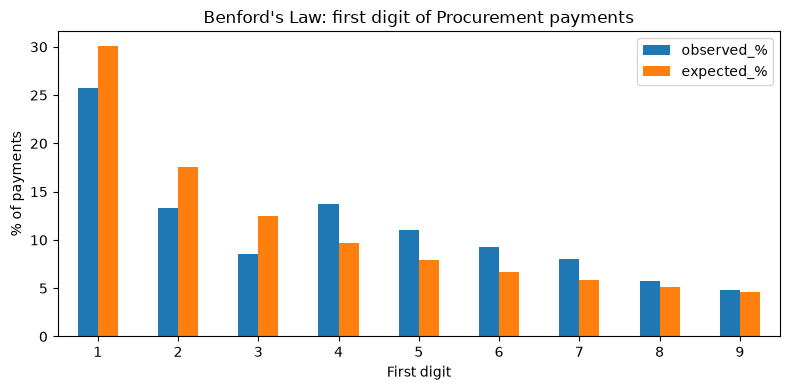

In [54]:
ax = bf[["observed_%", "expected_%"]].plot(kind="bar", figsize=(8, 4))
ax.set_xlabel("First digit")
ax.set_ylabel("% of payments")
ax.set_title("Benford's Law: first digit of Procurement payments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/benford_first_digit.png", dpi=150)
plt.show()

In [55]:
d = q("""
SELECT supplier_clean, amount FROM payments
WHERE spend_group = 'Procurement' AND supplier_clean <> 'REDACTED' AND amount >= 10
""")
d["first_digit"] = (d["amount"] / 10 ** np.floor(np.log10(d["amount"]))).astype(int)
fours = d[d["first_digit"] == 4]

print(f"Payments starting with 4: {len(fours):,}")
print("\nSuppliers with the most payments starting with 4:")
print(fours["supplier_clean"].value_counts().head(8).to_string())
print("\nMost repeated amounts starting with 4:")
print(fours["amount"].value_counts().head(8).to_string())

Payments starting with 4: 10,555

Suppliers with the most payments starting with 4:
supplier_clean
BRITISH GAS SOCIAL HOUSING LTD T A PH JONES             736
JEFF WAY CONSTRUCTION LTD                               657
ENTERPRISE RENT A CAR UK LTD T A FLEX E RENT            461
CAR HIRE DAY OF SWANSEA LTD T A DAYS RENTAL             458
DOMESTIC DRAIN SERVICES                                 380
MASTERS PIPELINE SERVICES LTD                           378
PREMIER PEOPLE SOLUTIONS LTD T A PREMIER PARTNERSHIP    298
M D BUILDING SERVICES LTD                               232

Most repeated amounts starting with 4:
amount
455.1    275
433.7    197
450.0    189
440.4    154
434.5    137
480.0    129
420.0    117
435.0     92


In [56]:
def benford(amounts):
    fd = (amounts / 10 ** np.floor(np.log10(amounts))).astype(int)
    obs = fd.value_counts(normalize=True).reindex(range(1, 10), fill_value=0).sort_index()
    return obs, (obs - expected).abs().mean()

# Count each supplier + amount combination only once
unique_amounts = d.drop_duplicates(["supplier_clean", "amount"])["amount"]
obs_u, mad_u = benford(unique_amounts)

print(f"All payments:   {len(d):,} tested, MAD {mad:.4f}")
print(f"Unique amounts: {len(unique_amounts):,} tested, MAD {mad_u:.4f}")

pd.DataFrame({
    "all_payments_%": (observed * 100).round(1),
    "unique_amounts_%": (obs_u * 100).round(1),
    "expected_%": (expected * 100).round(1),
})

All payments:   76,931 tested, MAD 0.0282
Unique amounts: 56,019 tested, MAD 0.0214


,all_payments_%,unique_amounts_%,expected_%
1,25.7,27.8,30.1
2,13.3,13.7,17.6
3,8.5,9.0,12.5
4,13.7,12.4,9.7
5,11.0,10.3,7.9
6,9.3,8.6,6.7
7,8.0,7.3,5.8
8,5.7,5.8,5.1
9,4.8,5.1,4.6


### Test 5 findings

- First digits of Procurement payments (£10 or more) do not follow Benford's Law: MAD **0.0282** over 76,931 payments, above the 0.015 level usually treated as non-conformity. There are too few payments starting with 1, 2 and 3, and too many starting with 4 to 7.
- Much of the excess of 4s comes from repeated fixed amounts (e.g. £455.10 paid 275 times; eight repairs, hire and building suppliers account for about a third of all payments starting with 4). Counting each supplier and amount combination only once lowers the MAD to **0.0214** (56,019 amounts), but it stays above 0.015.
- Most payments fall in a narrow range and many are standard rates, so some deviation is expected and is not on its own evidence of manipulation. Benford's Law is used here as a dataset-level check, not to flag individual payments.

## Combined flags and risk score

Each Procurement payment gets 1 point for every test it fails: possible duplicate pair (Test 1), round amount of £10,000 or more (Test 3), weekend date (Test 4), and payment date outside its file's month (from cleaning). Tests 2 and 5 describe the whole dataset, so they do not flag individual payments. The score is a simple count used to decide where to look first, not a probability of error.

In [57]:
conn.executescript("""
DROP TABLE IF EXISTS dup_pair_keys;
CREATE TEMP TABLE dup_pair_keys AS SELECT * FROM dup_pairs;

DROP TABLE IF EXISTS payment_flags;
CREATE TABLE payment_flags AS
SELECT *,
       flag_duplicate_pair + flag_round_large + flag_weekend + flag_date_mismatch AS risk_score
FROM (
    SELECT p.payment_id, p.supplier_clean, p.pay_date, p.report_month, p.amount,
           p.expense_type, p.service_area,
           CASE WHEN k.supplier_clean IS NOT NULL THEN 1 ELSE 0 END AS flag_duplicate_pair,
           CASE WHEN p.amount >= 10000
                 AND ABS(p.amount - ROUND(p.amount / 1000.0) * 1000) < 0.005
                THEN 1 ELSE 0 END AS flag_round_large,
           CASE WHEN strftime('%w', p.pay_date) IN ('0', '6') THEN 1 ELSE 0 END AS flag_weekend,
           p.date_mismatch AS flag_date_mismatch
    FROM payments p
    LEFT JOIN dup_pair_keys k
      ON k.supplier_clean = p.supplier_clean AND k.pay_date = p.pay_date
     AND k.amount = p.amount AND k.expense_type = p.expense_type
     AND k.service_area = p.service_area
    WHERE p.spend_group = 'Procurement' AND p.supplier_clean <> 'REDACTED'
);
""")

q("""
SELECT COUNT(*) AS procurement_payments,
       SUM(flag_duplicate_pair) AS duplicate_pairs,
       SUM(flag_round_large) AS round_large,
       SUM(flag_weekend) AS weekend,
       SUM(flag_date_mismatch) AS date_mismatch,
       SUM(risk_score >= 2) AS two_or_more_flags
FROM payment_flags
""")

,procurement_payments,duplicate_pairs,round_large,weekend,date_mismatch,two_or_more_flags
0,77971,430,638,8,65,47


In [58]:
q("""
SELECT payment_id, supplier_clean, pay_date, printf('%.2f', amount) AS amount, risk_score,
       flag_duplicate_pair AS dup, flag_round_large AS round_amt,
       flag_weekend AS weekend, flag_date_mismatch AS date_gap
FROM payment_flags
WHERE risk_score >= 2
ORDER BY amount DESC
LIMIT 12
""")

,payment_id,supplier_clean,pay_date,amount,risk_score,dup,round_amt,weekend,date_gap
0,7741,BRISTOL MISSING LINK LTD T A NEXT LINK HOUSING...,2024-05-23,75000.00,2,1,1,0,0
1,7742,BRISTOL MISSING LINK LTD T A NEXT LINK HOUSING...,2024-05-23,75000.00,2,1,1,0,0
2,52855,SHB SOLICITORS LTD CLIENT,2023-12-28,69000.00,2,0,1,0,1
3,102392,GEORGE TAYLOR LTD,2025-08-19,55000.00,2,0,1,0,1
4,141929,STEPHENS WILMOT LTD,2026-02-17,375000.00,2,0,1,0,1
5,100194,LYONS BOWE LTD CLIENT ACCOUNT,2024-08-31,370000.00,3,0,1,1,1
6,141916,HENRIQUES GRIFFITHS LLP,2026-02-27,368000.00,2,0,1,0,1
7,141917,HOTCHKISS WARBURTON SOLICITORS,2026-02-19,365000.00,2,0,1,0,1
8,122641,OCEAN PROPERTY LAWYERS LTD,2025-11-28,360000.00,2,0,1,0,1
9,6583,WSP UK LTD,2024-04-12,35000.00,2,1,1,0,0


### Priority review list

Round amounts and date gaps often occur together on property purchases paid through solicitors, which makes the plain "two or more flags" list noisy. The priority list therefore keeps payments that are a **possible duplicate pair plus at least one other flag**.

In [59]:
review = q("""
SELECT payment_id, supplier_clean, pay_date, printf('%.2f', amount) AS amount, expense_type,
       risk_score
FROM payment_flags
WHERE flag_duplicate_pair = 1 AND risk_score >= 2
ORDER BY CAST(amount AS REAL) DESC
""")
print(f"{len(review)} payments, £{review['amount'].astype(float).sum() / 1e6:.2f}m")
review.head(20)

22 payments, £2.28m


,payment_id,supplier_clean,pay_date,amount,expense_type,risk_score
0,99378,SLM LTD,2025-08-13,250000.00,External Professional Fees,2
1,99379,SLM LTD,2025-08-13,250000.00,External Professional Fees,2
2,24484,WINCKWORTH SHERWOOD LLP,2024-07-23,215000.00,Acquisition of Buildings,2
3,24486,WINCKWORTH SHERWOOD LLP,2024-07-23,215000.00,Acquisition of Buildings,2
4,24485,WINCKWORTH SHERWOOD LLP,2024-07-23,165000.00,Acquisition of Buildings,2
5,24487,WINCKWORTH SHERWOOD LLP,2024-07-23,165000.00,Acquisition of Buildings,2
6,93819,SLM LTD,2025-07-16,150000.00,External Professional Fees,2
7,93820,SLM LTD,2025-07-16,150000.00,External Professional Fees,2
8,35539,WEST OF ENGLAND COMBINED AUTHORITY,2024-09-06,110000.00,Services - Supplies and Services to service users,2
9,35540,WEST OF ENGLAND COMBINED AUTHORITY,2024-09-06,110000.00,Services - Supplies and Services to service users,2


### Suppliers with the most flagged payments

In [60]:
q("""
SELECT supplier_clean,
       COUNT(*) AS payments,
       SUM(risk_score > 0) AS flagged,
       ROUND(100.0 * SUM(risk_score > 0) / COUNT(*)) AS flagged_pct,
       ROUND(SUM(CASE WHEN risk_score > 0 THEN amount END) / 1e6, 2) AS flagged_millions
FROM payment_flags
GROUP BY supplier_clean
HAVING SUM(risk_score > 0) >= 5
ORDER BY flagged_millions DESC
LIMIT 12
""")

,supplier_clean,payments,flagged,flagged_pct,flagged_millions
0,SLM LTD,27,22,81.0,6.8
1,WINCKWORTH SHERWOOD LLP,18,11,61.0,2.7
2,HM COURTS AND TRIBUNAL SERVICE,24,24,100.0,2.7
3,ZURICH MUNICIPAL,32,30,94.0,2.4
4,AMERESCO LTD,1243,85,7.0,2.1
5,WILLMOTT DIXON CONSTRUCTION LTD,48,13,27.0,2.1
6,BRISTOL MISSING LINK LTD T A NEXT LINK HOUSING...,138,28,20.0,2.0
7,OCEAN PROPERTY LAWYERS LTD,12,7,58.0,1.9
8,LYONS BOWE LTD,5,5,100.0,1.4
9,FEEDING BRISTOL,8,6,75.0,1.4


## Summary of the unusual-payment tests

All tests use Procurement payments (excluding `REDACTED`). A flag marks a payment for review; it is **not** proof of error or fraud.

| Test | Result |
|---|---|
| 1. Possible duplicates | 215 pairs (same supplier, date, amount, spend type and service area; £5,000 or more), worth up to £5.9m. The **priority list** (a duplicate pair that is also a round amount) is 22 payments, about £1.1m if one payment per pair were an overpayment. |
| 2. Bunching below limits | None found: the round limits sit inside the range of the control amounts (1.1–1.4). |
| 3. Round amounts | 6.3% of payments of £10,000 or more are exact multiples of £1,000. They concentrate in a few suppliers, mostly law firms handling property purchases and suppliers on fixed-fee or instalment arrangements. |
| 4. Weekend payments | 13 of 141,930 payments (0.009%); the largest are property purchases at month-end. |
| 5. Benford's Law | MAD 0.0282 (0.0214 on unique amounts). Partly explained by repeated fixed rates; used as a dataset-level check only. |

### Recommendations

1. **Review the 11 priority pairs** (about £1.1m) against invoices and recover anything paid twice.
2. **Add a payment-run check** that holds a payment when the same supplier, amount, date and service area already exists, unless the invoice references differ.
3. **Publish an invoice or reference number** in the open spending data. Without it, outsiders cannot tell a duplicate from a genuine repeat payment.
4. **Treat property completions through solicitors separately** in routine monitoring, since they are round, large and often posted across month-ends, and so trigger most of the flags.

### Limits of this analysis

- The data has no invoice numbers, so no flagged payment can be confirmed as an error.
- A few public bodies (e.g. HM Courts and Tribunal Service, West of England Combined Authority) remain in Procurement.
- June 2025 could not be reconciled to a council total because that file has no total row.
- The approval limits used in Test 2 are illustrative; the council's real limits are not in the data.